# Empirical Analysis Notebook
## Edge-Indexed Network Time Series with Graph Ornstein-Uhlenbeck Dynamics
### Chen & Veraart (2026)

This notebook reproduces the empirical results of **Sections 4–5** of the paper, covering three main components:

---

### 1. LOBSTER Data Processing & MRC Covariance Estimation (Section 5)
- Pre-process high-frequency limit order book data for **8 U.S. assets** from the LOBSTER database
- Compute **hourly realized covariance/correlation** via the MRC estimator (Christensen, Kinnebrock & Podolskij 2010, Appendix F)
- **Training set:** 2023-01-01 to 2025-06-30 | **Testing set:** 2025-07-01 to 2026-02-01

### 2. Empirical Forecasting Study (Sections 5.2–5.3)
- Fit and evaluate all **benchmark models** (NA, UAR, VAR, GNAR, OU, MCAR, grOU) on realized covariance time series
- Select the best grOU specification via **BIC** (Equation 5.1, Figure 22)
- Perform **joint graph-model selection** over 1000 Erdős-Rényi candidate networks (Figure 23)

### 3. Monte Carlo Simulation Study (Section 4)
- Assess **finite-sample consistency** of the grOU estimator at $t = 2, 4, 8$ (Figures 3–5)
- Compare **forecasting performance** across models under three noise regimes (BM, CP, Gamma) and three network misspecification scenarios (Figures 8–19)

---

### Assets (Section 5)
| Ticker | Company |
|--------|---------|
| SPY  | SPDR S&P 500 ETF Trust |
| AMZN | Amazon.com Inc. |
| JPM  | JPMorgan Chase & Co. |
| GS   | Goldman Sachs Group Inc. |
| KO   | The Coca-Cola Company |
| MSFT | Microsoft Corporation |
| NDAQ | Nasdaq Inc. |
| MNST | Monster Beverage Corporation |

## Cell 1: Global Configuration

Key hyperparameters used throughout the notebook:

| Parameter | Value | Description |
|-----------|-------|-------------|
| `C` | 1 | Number of edge-weight covariate matrices |
| `rule` | `'h'` | MRC aggregation interval (hourly) |
| `sample_interval` | `'1s'` | LOB resampling interval (1-second mid-quotes) |
| `forecast_step` | 1 | One-step-ahead forecasting horizon |
| `gamma` | 1.01 | Critical region hyperparameter $\gamma > 1$|

The critical region hyperparameter $\gamma$ controls the component-wise jump-filtering
threshold sequence $\nu$, chosen via `choose_nu` (see `mcar/estimate.py`), which
separates the continuous Brownian component from the jump component of the driving
Lévy process. A value close to 1 gives a tight critical region that captures most
Brownian increments while filtering jump-dominated ones.

In [1]:
import pickle
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

TICKERS = ['SPY', 'AMZN', 'JPM', 'GS', 'KO', 'MSFT', 'NDAQ', 'MNST']
C = 1
rule = 'h'
sample_interval = '1s'
forecast_step = 1
gamma = 1.01

## Cell 2: LOBSTER Data Processing Pipeline (Pre-Computed)

> **Note:** This cell is commented out as the processed data is pre-computed. Training and testing **correlation** and **covariance** data derived from the real-time log data are stored in
`/data/LOBSTERdata/output/train/aggregate/` and `/data/LOBSTERdata/output/test/aggregate/`, respectively.

The processing pipeline (see `process_orderbook` in `data_process.py`) applies the following steps per trading day:

1. Load order book (`ASKp1`, `BIDp1`) and message book (timestamps, event types)
2. Compute mid-quote: $\text{mid}_t = (\text{ASK}_{p1,t} + \text{BID}_{p1,t}) / 2$
3. Remove **trading halts** (event type 7)
4. Remove **crossed quotes** ($\text{BID}_{p1} > \text{ASK}_{p1}$)
5. Collapse simultaneous timestamps (keep last state per second)
6. Restrict to regular market hours (9:30–16:00)
7. Drop first and last **60 minutes** of trading
8. Resample to **1-second** frequency with forward-fill

The **MRC estimator** (Appendix F, Christensen et al. 2010) then pre-averages high-frequency
increments to reduce microstructure noise before computing hourly covariance/correlation matrices,
with parameters $\delta = 0.6$, $\theta = 1$.

In [ ]:
'''
# Data Processing
# Training set
for TICKER in TICKERS:
    input_path = './data/LOBSTERdata/_' + TICKER + '_2023-01-01_2025-06-30'
    log_path = './data/LOBSTERdata/log/train/' + TICKER + '_processing_logs'
    os.makedirs(log_path, exist_ok=True)
    output_path = './data/LOBSTERdata/output/train/' + TICKER
    os.makedirs(output_path, exist_ok=True)
    multiprocess_orderbooks(TICKER=TICKER, input_path=input_path, output_path=output_path, log_path=log_path, check_for_processed_data=True, sample_interval=sample_interval)

aggregate_assets(TICKERS, './data/LOBSTERdata/output/train/', './data/LOBSTERdata/output/train/aggregate/')

# Testing set
for TICKER in TICKERS:
    input_path = './data/LOBSTERdata/_' + TICKER + '_2025-07-01_2026-02-01'
    log_path = './data/LOBSTERdata/log/test/' + TICKER + '_processing_logs'
    os.makedirs(log_path, exist_ok=True)
    output_path = './data/LOBSTERdata/output/test/' + TICKER
    os.makedirs(output_path, exist_ok=True)
    multiprocess_orderbooks(TICKER=TICKER, input_path=input_path, output_path=output_path, log_path=log_path, check_for_processed_data=True, sample_interval=sample_interval)
    
aggregate_assets(TICKERS, './data/LOBSTERdata/output/test/', './data/LOBSTERdata/output/test/aggregate/')

# Compute and save correlation/covariance data
log_data_to_corr_data('./data/LOBSTERdata/output/train/aggregate/', rule, delta=.6, theta=1)
log_data_to_corr_data('./data/LOBSTERdata/output/test/aggregate/', rule, delta=.6, theta=1)
log_data_to_corr_data('./data/LOBSTERdata/output/train/aggregate/', rule, delta=.6, theta=1, is_corr=False)
log_data_to_corr_data('./data/LOBSTERdata/output/test/aggregate/', rule, delta=.6, theta=1, is_corr=False)
'''

## Cell 3: SPY–NDAQ Correlation and Covariance (Figure 20)

Plots the hourly pre-averaged **correlation** (left axis, blue) and **covariance** (right axis, red)
between SPY and NDAQ from 2023-01-01 to 2025-07-01.

Key observations motivating the Lévy-driven grOU model:
- **Correlation** exhibits occasional abrupt structural shifts
- **Covariance** displays several large jumps, including a cluster around **April 2025**

This jump behavior motivates the use of a Lévy process (rather than pure Brownian motion)
as the driving noise in the grOU framework.

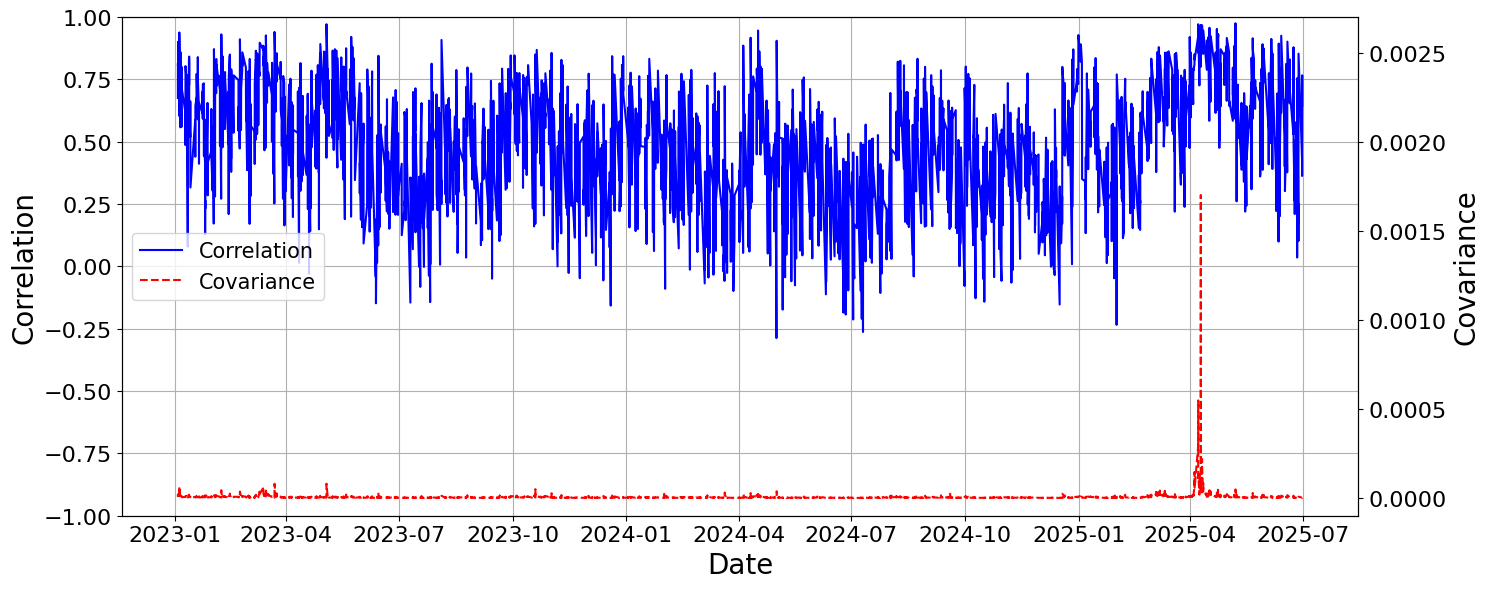

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


In [2]:
# Load pre-computed MRC correlation and covariance data
data_corr = np.load('./data/LOBSTERdata/output/train/aggregate/corr.npz', allow_pickle=True)
index = pd.to_datetime(data_corr['timestamps'])
df_corr = pd.DataFrame({key: data_corr[key] for key in data_corr.files if key != 'timestamps'}, index=index)

data_cov = np.load('./data/LOBSTERdata/output/train/aggregate/cov.npz', allow_pickle=True)
index = pd.to_datetime(data_cov['timestamps'])
df_cov = pd.DataFrame({key: data_cov[key] for key in data_cov.files if key != 'timestamps'}, index=index)

df = pd.DataFrame({"Correlation": df_corr['SPY_NDAQ'], "Covariance": df_cov['SPY_NDAQ']}).dropna()

fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(df.index, df["Correlation"], label="Correlation", linestyle='-', color='blue')
ax1.set_xlabel("Date", fontsize=20)
ax1.set_ylabel("Correlation", fontsize=20)
ax1.set_ylim(-1,1)
ax1.grid(True)
ax1.tick_params(axis='both', labelsize=16)

ax2 = ax1.twinx()
ax2.set_ylim(-0.0001,0.0027)
ax2.plot(df.index, df["Covariance"], label="Covariance", linestyle='--', color='red')
ax2.set_ylabel("Covariance", fontsize=20)
ax2.tick_params(axis='both', labelsize=16)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left", fontsize=15)

plt.tight_layout()
plt.show()
fig.savefig('./data/LOBSTERdata/output/train/aggregate/corr_cov.eps', format='eps')

## Cell 4: Load Training Data and Define Network Structure (Figure 21)

Loads the hourly MRC covariance time series and defines the **8-asset financial network**
shown in Figure 21 of the paper.

The network encodes potential economic relationships among assets:
- **SPY** is connected to all assets (broad market index)
- **Financial sector** (JPM, GS) are connected to each other and to SPY
- **Technology** (MSFT, AMZN, NDAQ) share connections
- **Consumer staples** (KO, MNST) have sparser connections

### Time Grid Setup (Section 5.1, Appendix C)
- **Fine grid** $\mathcal{P}$: $\Delta_P = 0.01$
- **Coarse grid** $\mathcal{Q}$: grid ratio of 18, i.e. $\Delta_Q = 18 \cdot \Delta_P = 0.18$

The ratio of 18 is a pragmatic compromise between theoretical optimality and numerical
stability under microstructure noise, as discussed in Section 5.1.

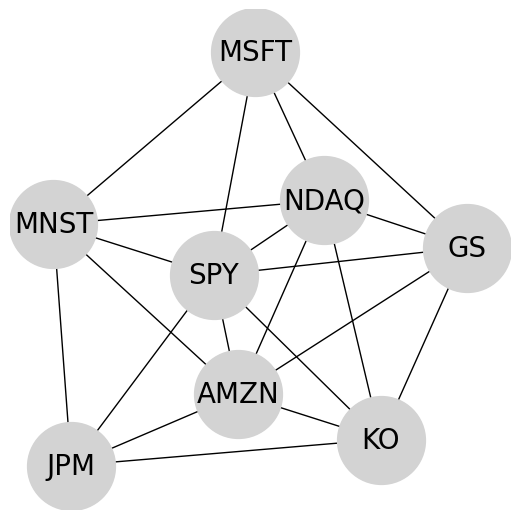

In [3]:
# Load hourly MRC covariance training data
data = np.load('./data/LOBSTERdata/output/train/aggregate/cov.npz', allow_pickle=True)
index = pd.to_datetime(data['timestamps'])
_data = pd.DataFrame({key: data[key] for key in data.files if key != 'timestamps'}, index=index)

# Node-level adjacency matrix A (Figure 21)
A = [[0, 1, 1, 1, 1, 1, 1, 1],
       [1, 0, 1, 1, 1, 0, 1, 1],
       [1, 1, 0, 0, 1, 0, 0, 1],
       [1, 1, 0, 0, 1, 1, 1, 0],
       [1, 1, 1, 1, 0, 0, 1, 0],
       [1, 0, 0, 1, 0, 0, 1, 1],
       [1, 1, 0, 1, 1, 1, 0, 1],
       [1, 1, 1, 0, 0, 1, 1, 0]]

G = nx.from_numpy_array(np.array(A))
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
pos = nx.spring_layout(G, seed=1)

plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_size=4000, node_color='lightgrey', font_size=20)
plt.savefig('./data/LOBSTERdata/output/train/aggregate/network.eps', format='eps')
plt.show()

# Convert to edge-level line graph and extract edge processes
Adj = adj_to_line_graph(A, TICKERS)
K = Adj[0].shape[0]
Y = _data[Adj[1]].T

# Fine and coarse time grids
P_ = np.array([0.01 * i for i in range(Y.shape[1])])
delta = 18
Q_ = np.append(P_[::delta], P_[-1]) if (Y.shape[1] - 1) % delta != 0 else P_[::delta]

# Load test data
test_data = np.load('./data/LOBSTERdata/output/test/aggregate/cov.npz', allow_pickle=True)
test_index = pd.to_datetime(test_data['timestamps'])
test_data_ = pd.DataFrame({key: test_data[key] for key in test_data.files if key != 'timestamps'}, index=test_index)
test_Y = test_data_[Adj[1]].T
test_set = sliding_window_view(test_Y, (K, forecast_step))[0]
test_size = test_set.shape[0]

## Cell 5: BIC-Based Model Selection for Known Network (Figure 22)

Evaluates all candidate grOU specifications for the known network (Figure 21) using the
**Bayesian Information Criterion** (Section 5.2, Equation 5.1):

$$\text{BIC} = -\hat{\theta}^\top [\mathbf{K}] \hat{\theta} + \left(LK + \sum_{l=1}^L R_l\right) \log(N)$$

where:
- $\hat{\theta}^\top [\mathbf{K}] \hat{\theta}$: log-likelihood contribution
- $LK + \sum_{l=1}^L R_l$: total number of drift parameters
- $N$: number of coarse-grid increments

**Candidate models:** $\text{grOU}(L, [r, \ldots, r])$ for $L \in \{1, 2, 3\}$ and $r \in \{1, 2\}$

Lower BIC indicates a better (more parsimonious) model.

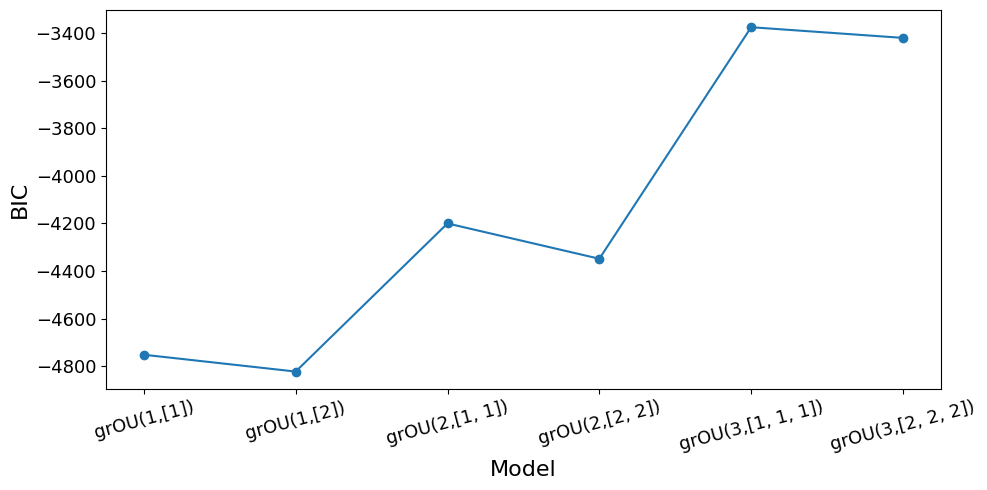

[np.float64(-4752.3563057659185),
 np.float64(-4823.067799733002),
 np.float64(-4200.01336443266),
 np.float64(-4348.603472218298),
 np.float64(-3374.691154243391),
 np.float64(-3419.5798452019385)]

In [4]:
models = [[value] * length for length in range(1, 4) for value in (1, 2)]
bic = [grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, model, C, P_, Q_, gamma, is_global=False, print_param=True, is_test=True)[2] for model in models]

plt.figure(figsize=(10, 5))
plt.plot(['grOU(' + str(len(model)) + ',' + str(model) + ')' for model in models], bic, marker="o")
plt.xlabel("Model", fontsize=16)
plt.ylabel("BIC", fontsize=16)
plt.xticks(rotation=15)
plt.tick_params(axis='both', labelsize=13)
plt.tight_layout()
plt.savefig('./data/LOBSTERdata/output/train/aggregate/bic.eps', format='eps')
plt.show()

bic

## Cell 5b: Forecasting Comparison for Known Network (Table 1)

One-step-ahead forecasting evaluation on the **known network** (Figure 21),
reproducing **Table 1** of Chen & Veraart (2026).

All continuous-time models (OU, MCAR, grOU) use the exact conditional mean
prediction from **Proposition 2.2**:
$$\mathbb{E}[Y_{t+h} \mid \mathcal{F}_t] = \mathbb{E}[Y_0] + \mathbf{A} e^{\mathbb{Q}h} [\mathbf{X}_t - \mathbb{E}[\mathbf{X}_0]]$$

**Evaluation metrics:**
- **RMSE:** $\sqrt{\frac{1}{TK} \sum_{t,k} (Y_t^{(k)} - \hat{Y}_t^{(k)})^2}$
- **DirAcc:** $\frac{1}{TK} \sum_{t,k} \mathbf{1}\left\{\text{sgn}(Y_t^{(k)} - Y_{t-1}^{(k)}) = \text{sgn}(\hat{Y}_t^{(k)} - Y_{t-1}^{(k)})\right\}$

The naive model achieves DirAcc = 0.5 by convention.

Models evaluated (Table 1):

| Model | Description |
|-------|-------------|
| NA | Naive: $\hat{Y}_{t+1} = Y_t$ |
| AR | Univariate AR(1) per edge (OLS) |
| VAR | Vector AR(1) for all edges jointly (OLS) |
| GNAR | Generalized Network AR edge model (Mantziou et al. 2023) |
| OU | Diagonal OU model (no network structure) |
| MCAR | Full MCAR model (unconstrained $K \times K$ drift matrices) |
| grOU(1,[1]) | Graph OU, lag=1, 1-stage neighborhood |
| grOU(1,[2]) | Graph OU, lag=1, 2-stage neighborhood |
| grOU(2,[1,1]) | Graph OU, lag=2, 1-stage neighborhood |
| grOU(2,[2,2]) | Graph OU, lag=2, 2-stage neighborhood |
| grOU(3,[1,1,1]) | Graph OU, lag=3, 1-stage neighborhood |
| grOU(3,[2,2,2]) | Graph OU, lag=3, 2-stage neighborhood |

In [5]:
results = {}

# ---- Naive model (DirAcc baseline = 0.5) ----
forecast_NA, NA_RMSE = NA_model(Y, test_set, forecast_step)
results['NA'] = {'RMSE': NA_RMSE, 'DirAcc': 0.5, 'Time(s)': '-'}

# ---- Univariate AR(1) edge model ----
start = time.perf_counter()
forecast_AR = UAR_model(Y, test_set, test_size, forecast_step, 1)
AR_RMSE, AR_dir = evaluate_forecast(Y, forecast_AR, test_set)
results['AR'] = {'RMSE': AR_RMSE, 'DirAcc': AR_dir, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- Vector AR(1) edge model ----
start = time.perf_counter()
forecast_VAR = VAR_model(Y, test_set, test_size, forecast_step, 1)
VAR_RMSE, VAR_dir = evaluate_forecast(Y, forecast_VAR, test_set)
results['VAR'] = {'RMSE': VAR_RMSE, 'DirAcc': VAR_dir, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- GNAR edge model (Mantziou et al. 2023) ----
start = time.perf_counter()
forecast_GNAR = GNAR_model(Y, Adj, [1], test_set, test_size, forecast_step)
GNAR_RMSE, GNAR_dir = evaluate_forecast(Y, forecast_GNAR, test_set)
results['GNAR'] = {'RMSE': GNAR_RMSE, 'DirAcc': GNAR_dir, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- OU edge model (diagonal drift, no network structure) ----
start = time.perf_counter()
forecast_OU = OU_edge_model(Y, test_set, test_size, forecast_step, [1], C, P_, Q_, gamma, is_global=False)
OU_RMSE, OU_dir = evaluate_forecast(Y, forecast_OU, test_set)
results['OU'] = {'RMSE': OU_RMSE, 'DirAcc': OU_dir, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- MCAR edge model (unconstrained K×K drift matrices) ----
start = time.perf_counter()
forecast_MCAR = MCAR_edge_model(Y, test_set, test_size, forecast_step, P_, Q_, [1], C, gamma)
MCAR_RMSE, MCAR_dir = evaluate_forecast(Y, forecast_MCAR, test_set)
results['MCAR'] = {'RMSE': MCAR_RMSE, 'DirAcc': MCAR_dir, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- grOU edge models: all candidate specifications ----
grOU_specs = {
    'grOU(1,[1])':   [1],
    'grOU(1,[2])':   [2],
    'grOU(2,[1,1])': [1, 1],
    'grOU(2,[2,2])': [2, 2],
    'grOU(3,[1,1,1])': [1, 1, 1],
    'grOU(3,[2,2,2])': [2, 2, 2],
}

for label, R_L in grOU_specs.items():
    start = time.perf_counter()
    forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step,
                                    R_L, C, P_, Q_, gamma, is_global=False)
    rmse, dacc = evaluate_forecast(Y, forecast_grOU, test_set)
    results[label] = {'RMSE': rmse, 'DirAcc': dacc, 'Time(s)': round(time.perf_counter() - start, 4)}

# ---- Display results as Table 1 ----
df_results = pd.DataFrame(results).T
df_results.index.name = 'Model'
df_results['RMSE'] = df_results['RMSE'].apply(lambda x: f'{x:.4e}' if isinstance(x, float) else x)
df_results['DirAcc'] = df_results['DirAcc'].apply(lambda x: f'{x:.4f}' if isinstance(x, float) else x)
print("Table 1: One-step forecast results for the known network (Figure 21)\n")
print(df_results.to_string())

Table 1: One-step forecast results for the known network (Figure 21)

                       RMSE  DirAcc  Time(s)
Model                                       
NA               7.2826e-06  0.5000        -
AR               6.4733e-06  0.5871   0.7503
VAR              1.3365e-05  0.5736   2.4617
GNAR             6.6976e-06  0.6487    6.445
OU               7.2133e-06  0.6617   9.7892
MCAR             7.1677e-06  0.6078  14.0193
grOU(1,[1])      7.2175e-06  0.6717    6.089
grOU(1,[2])      7.2180e-06  0.6687    6.104
grOU(2,[1,1])    7.2837e-06  0.5014   8.3981
grOU(2,[2,2])    7.2840e-06  0.4986   8.6811
grOU(3,[1,1,1])  7.2805e-06  0.5186  14.2311
grOU(3,[2,2,2])  7.2804e-06  0.5234  15.0008


## Cell 6: Joint Graph-Model Selection (Section 5.3)

Implements the **two-stage joint network and model selection** procedure when the
underlying network is unknown:

**Stage 1 — Network Screening:**
1. Generate $n = 1000$ Erdős-Rényi graphs $G(8, 0.4)$ as candidate networks
   (edge probability $p = 0.4$ ensures high connectivity)
2. Evaluate each using the screening model $\text{grOU}(1,[1])$
3. Retain the **top 50** networks by directional accuracy (BIC as tiebreaker within tolerance $10^{-2}$)

**Stage 2 — Model Selection:**
4. For each retained network, search over candidate grOU specifications
   $([r]^L$ for $L \in \{1,2,3\}$, $r \in \{1,2\})$
5. Select the best model per network by directional accuracy and BIC

**Final Selection:**
6. Among all 50 (network, model) pairs, return $(\hat{G}, \hat{M})$ with the best
   directional accuracy (BIC as tiebreaker)

Results are saved to disk for reproducibility.

In [3]:
result = joint_graph_model_selection(_data, test_data_, TICKERS, [1], P_, Q_, forecast_step, C, gamma, n_candidates=1000, top_k=50, max_order=3, tol=1e-2, p=0.4)
with open("./data/LOBSTERdata/output/train/aggregate/model_selection.pkl", "wb") as f:
    pickle.dump(result, f)

=== Step 1-4: Network screening ===

=== Step 5: Model selection within each retained network ===

=== Final selection ===
Selected model: [2]
Selected final result: [np.float64(0.6982475355969332), array([[0., 0., 0., 0., 1., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 1.],
       [0., 1., 0., 1., 1., 1., 0., 1.],
       [0., 0., 1., 0., 1., 1., 0., 1.],
       [1., 0., 1., 1., 0., 0., 0., 0.],
       [0., 0., 1., 1., 0., 0., 1., 1.],
       [0., 0., 0., 0., 0., 1., 0., 1.],
       [1., 1., 1., 1., 0., 1., 1., 0.]]), np.float64(-1047.4379745895765)]


## Cell 7: Display Joint Selection Results (Figure 23)

Loads and displays the selected $(\hat{G}, \hat{M})$ pair from the joint selection procedure.

The selected network (Figure 23) is **relatively sparse**, connecting the main cross-asset
relationships. The selected model $\text{grOU}(1,[2])$ combines:
- A **network structure** (missing from the OU model)
- A **continuous-time framework** that better captures jump dynamics than GNAR

Selected model: [2]
Selected directional accuracy: 0.6982475355969332
Selected network: [[0. 0. 0. 0. 1. 0. 0. 1.]
 [0. 0. 1. 0. 0. 0. 0. 1.]
 [0. 1. 0. 1. 1. 1. 0. 1.]
 [0. 0. 1. 0. 1. 1. 0. 1.]
 [1. 0. 1. 1. 0. 0. 0. 0.]
 [0. 0. 1. 1. 0. 0. 1. 1.]
 [0. 0. 0. 0. 0. 1. 0. 1.]
 [1. 1. 1. 1. 0. 1. 1. 0.]]
Selected bic: -1047.4379745895765


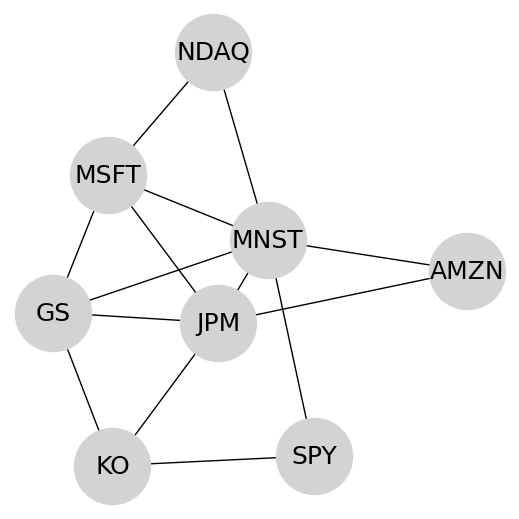

In [6]:
with open("./data/LOBSTERdata/output/train/aggregate/model_selection.pkl", "rb") as f:
    model_selection = pickle.load(f)
print(f"Selected model: {model_selection['Selected model']}")
print(f"Selected directional accuracy: {model_selection['Selected final result'][0]}")
print(f"Selected network: {model_selection['Selected final result'][1]}")
print(f"Selected bic: {model_selection['Selected final result'][2]}")

G = nx.from_numpy_array(np.array(model_selection['Selected final result'][1]))
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
pos = nx.spring_layout(G, seed=2)

plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightgrey', font_size=18)
plt.savefig('./data/LOBSTERdata/output/train/aggregate/selected_network.eps', format='eps')
plt.show()

## Cell 8: Prepare Data for Selected Network

Extracts the edge processes and sets up time grids for the **selected network** from Cell 7.

The same fine/coarse grid setup as Cell 4 is applied:
- Fine grid $\mathcal{P}$: $\Delta_P = 0.01$
- Coarse grid $\mathcal{Q}$: grid ratio of 18

In [7]:
Adj = adj_to_line_graph(model_selection['Selected final result'][1], TICKERS)
K = Adj[0].shape[0]
Y = _data[Adj[1]].T

P_ = np.array([0.01 * i for i in range(Y.shape[1])])
delta = 18
Q_ = np.append(P_[::delta], P_[-1]) if (Y.shape[1] - 1) % delta != 0 else P_[::delta]

test_data = np.load('./data/LOBSTERdata/output/test/aggregate/cov.npz', allow_pickle=True)
test_index = pd.to_datetime(test_data['timestamps'])
test_data_ = pd.DataFrame({key: test_data[key] for key in test_data.files if key != 'timestamps'}, index=test_index)
test_Y = test_data_[Adj[1]].T
test_set = sliding_window_view(test_Y, (K, forecast_step))[0]
test_size = test_set.shape[0]

## Cell 9: Empirical Forecasting Comparison (Table 2)

One-step-ahead forecasting evaluation on the **selected network's edge processes**.

All continuous-time models (OU, MCAR, grOU) use the exact conditional mean prediction
from **Proposition 2.2** of Chen & Veraart (2026):
$$\mathbb{E}[Y_{t+h} \mid \mathcal{F}_t] = \mathbb{E}[Y_0] + \mathbf{A} e^{\mathbb{Q}h} [\mathbf{X}_t - \mathbb{E}[\mathbf{X}_0]]$$

**Evaluation metrics:**
- **RMSE:** $\sqrt{\frac{1}{TK} \sum_{t,k} (Y_t^{(k)} - \hat{Y}_t^{(k)})^2}$
- **DirAcc:** $\frac{1}{TK} \sum_{t,k} \mathbf{1}\left\{\text{sgn}(Y_t^{(k)} - Y_{t-1}^{(k)}) = \text{sgn}(\hat{Y}_t^{(k)} - Y_{t-1}^{(k)})\right\}$

The naive model achieves DirAcc = 0.5 by convention.

In [9]:
forecast_NA, NA_RMSE_mean = NA_model(Y, test_set, forecast_step)
print(f'NA          — RMSE: {NA_RMSE_mean:.4e}')

start = time.perf_counter()
forecast_AR = UAR_model(Y, test_set, test_size, forecast_step, 1)
AR_RMSE_mean, AR_dir_mean = evaluate_forecast(Y, forecast_AR, test_set)
print(f'UAR         — Time: {time.perf_counter()-start:.2f}s | RMSE: {AR_RMSE_mean:.4e} | DirAcc: {AR_dir_mean:.4f}')

start = time.perf_counter()
forecast_VAR = VAR_model(Y, test_set, test_size, forecast_step, 1)
VAR_RMSE_mean, VAR_dir_mean = evaluate_forecast(Y, forecast_VAR, test_set)
print(f'VAR         — Time: {time.perf_counter()-start:.2f}s | RMSE: {VAR_RMSE_mean:.4e} | DirAcc: {VAR_dir_mean:.4f}')

start = time.perf_counter()
forecast_GNAR = GNAR_model(Y, Adj, [1], test_set, test_size, forecast_step)
GNAR_RMSE_mean, GNAR_dir_mean = evaluate_forecast(Y, forecast_GNAR, test_set)
print(f'GNAR        — Time: {time.perf_counter()-start:.2f}s | RMSE: {GNAR_RMSE_mean:.4e} | DirAcc: {GNAR_dir_mean:.4f}')

start = time.perf_counter()
forecast_OU = OU_edge_model(Y, test_set, test_size, forecast_step, [1], C, P_, Q_, gamma, is_global=False)
OU_RMSE_mean, OU_dir_mean = evaluate_forecast(Y, forecast_OU, test_set)
print(f'OU          — Time: {time.perf_counter()-start:.2f}s | RMSE: {OU_RMSE_mean:.4e} | DirAcc: {OU_dir_mean:.4f}')

start = time.perf_counter()
forecast_MCAR = MCAR_edge_model(Y, test_set, test_size, forecast_step, P_, Q_, [1], C, gamma)
MCAR_RMSE_mean, MCAR_dir_mean = evaluate_forecast(Y, forecast_MCAR, test_set)
print(f'MCAR        — Time: {time.perf_counter()-start:.2f}s | RMSE: {MCAR_RMSE_mean:.4e} | DirAcc: {MCAR_dir_mean:.4f}')

for R_L, label in [([2],'grOU(1,[2])')]:
    start = time.perf_counter()
    forecast_grOU = grOU_edge_model(Y, Adj, test_set, test_size, forecast_step, R_L, C, P_, Q_, gamma, is_global=False)
    rmse, dacc = evaluate_forecast(Y, forecast_grOU, test_set)
    print(f'{label:<18} — Time: {time.perf_counter()-start:.2f}s | RMSE: {rmse:.4e} | DirAcc: {dacc:.4f}')

NA          — RMSE: 9.0310e-06
UAR         — Time: 0.51s | RMSE: 7.6085e-06 | DirAcc: 0.5997
VAR         — Time: 2.29s | RMSE: 1.2097e-05 | DirAcc: 0.5772
GNAR        — Time: 3.15s | RMSE: 7.9201e-06 | DirAcc: 0.6878
OU          — Time: 5.12s | RMSE: 8.9642e-06 | DirAcc: 0.6923
MCAR        — Time: 6.59s | RMSE: 8.9342e-06 | DirAcc: 0.6121
grOU(1,[2])        — Time: 4.32s | RMSE: 8.9568e-06 | DirAcc: 0.6982


## Cell 10: Simulation Study Setup — Consistency Experiment (Section 4.1)

Sets up the $\text{grOU}(2,[1,1])$ model for the **3-node, 2-edge undirected network** (Figure 2):
$$a \text{ —} e_1 \text{— } b \text{ —} e_2 \text{— } c$$

**True parameters** ($\alpha^*$, $\beta^*$):
$$\alpha^* = \begin{bmatrix} 4 & 2 \\ 3 & 1 \end{bmatrix}, \quad \beta^* = [1, 1]^\top$$

where $\alpha^*_{i,j}$ is the autoregressive coefficient for edge $i$ at lag $j$.

**Three noise regimes** (Lévy triplet $(0, I_2, F)$):
- **BM:** Pure Brownian motion ($F = 0$)
- **CP:** Compound Poisson, rate $\lambda = 1$, jump sizes $\mathcal{N}(0, I_2)$
- **Gamma:** Independent symmetric Gamma, shape $k=1$, scale $\theta=1$

**Grid parameters** (Lucchese et al. 2026, Section 4.4):
- Fine grid: $\Delta_P = t^{-6}$ (i.e., $N = t^7$ steps)
- Coarse grid: $\Delta_Q = t^{-2}$

The jump-filtering threshold sequence $\nu$ is chosen via `choose_nu`
(see `mcar/estimate.py`) at each time horizon.

In [2]:
adj_sim = adj_to_line_graph([[0,1,0],[1,0,1],[0,1,0]], ['a','b','c'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)

X_sim = GraphOUEdge([1,1], 2, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim')
X_sim.alpha_set(np.array([[4,3],[2,1]]))
X_sim.beta_set([[1],[1]])
X_sim.Q_matrix()

array([[ 0.,  0.,  1.,  0.],
       [ 0.,  0.,  0.,  1.],
       [-2., -1., -4., -1.],
       [-1., -1., -1., -3.]])

## Cell 11: Simulate and Estimate — Consistency Study (Pre-Computed)

> **Note:** This cell is commented out as the estimates are pre-computed. Uncomment to re-run.

For each noise regime, simulates **1000 Monte Carlo paths** (25 batches × 40 paths) at the
full $T = 8$ horizon, then estimates grOU parameters at $t = 2, 4, 8$ using `process_one_sim`.

Each call to `process_one_sim` subsets the path to the appropriate length and grid resolution,
runs the full iterative estimation (`estimate_MCAR`) to obtain $(\hat{b}, \hat{\Sigma})$,
then calls `estimate_grOU_drift` to obtain $\hat{\theta}$.

In [ ]:
'''
for regime in ['BM', 'CP', 'Gamma']:
    estimate = []
    for j in range(25):
        sim = X_sim.simulate(regime, 40, seed=134 + 100 * j, rate=1)
        P = np.linspace(0, 8, 8 ** 7 + 1)
        args = [(P, [1,1], 2, 1, sim[i], adj_L_sim, W_C_sim, gamma) for i in range(40)]
        with Pool(os.cpu_count()) as pool:
            results = pool.map(process_one_sim, args)
        estimate.extend(results)

    with open('./data/LOBSTERdata/output/sim/estimate_' + regime + '.npy', 'wb') as f:
        np.save(f, estimate)
'''

## Cell 12: Consistency Results — Contour Density Plots (Figures 3–5)

For each noise regime, plots a **3×3 grid of 2D KDE contour plots** showing the joint
empirical distribution of estimated parameter pairs at $t = 2, 4, 8$:

| Row | Parameters | True values |
|-----|-----------|-------------|
| 1 | $(\alpha_{1,1}, \alpha_{2,1})$ — lag 1 autoregressive | $(4, 3)$ |
| 2 | $(\alpha_{1,2}, \alpha_{2,2})$ — lag 2 autoregressive | $(2, 1)$ |
| 3 | $(\beta_1, \beta_2)$ — network interaction | $(1, 1)$ |

Each panel shows a **2D Gaussian KDE** of the 1000 Monte Carlo estimates, with the true
parameter value marked as a **red dot**. Increasing concentration around the true value
as $t$ grows provides empirical support for **Theorem 3.2** (weak consistency).

> Outliers with $|\hat{\theta}| > 100$ are removed before KDE fitting to avoid numerical issues.

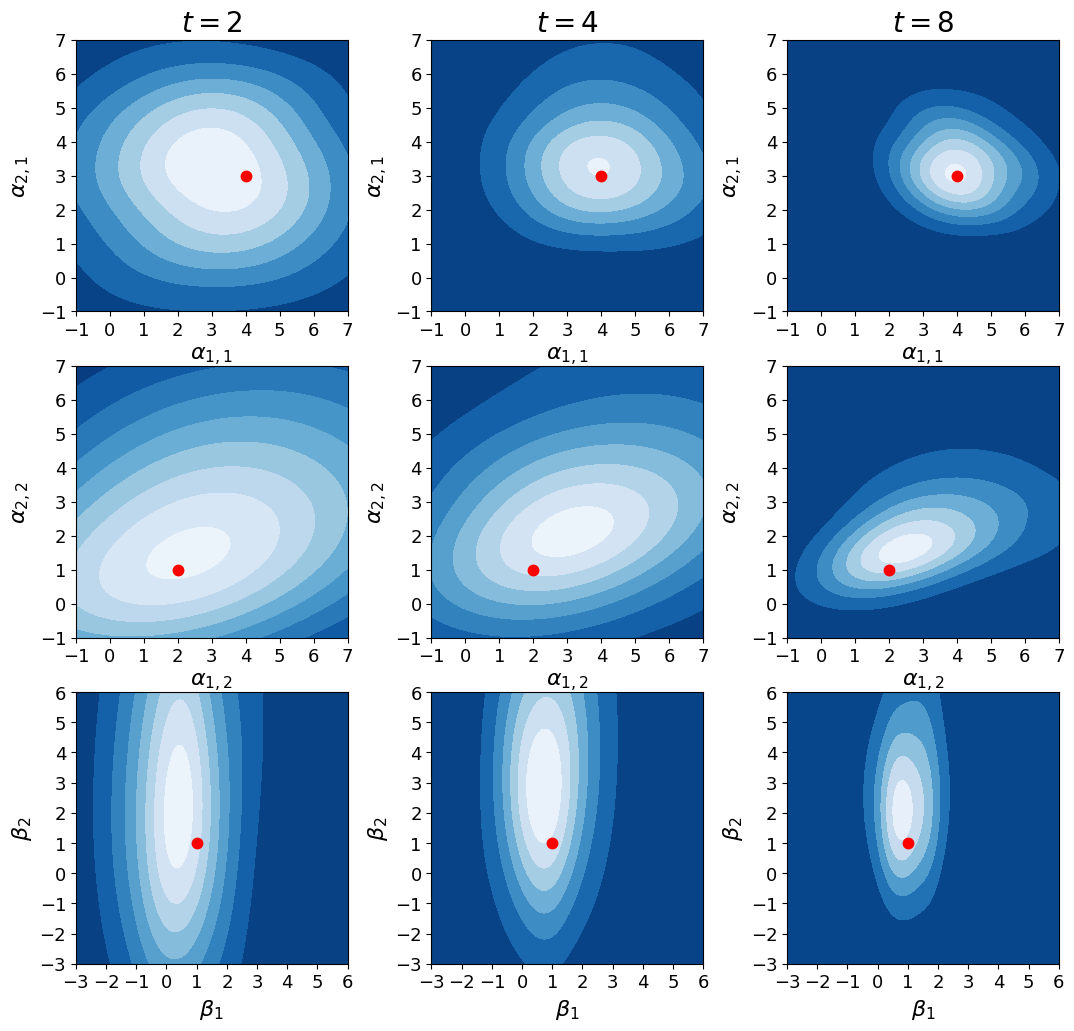

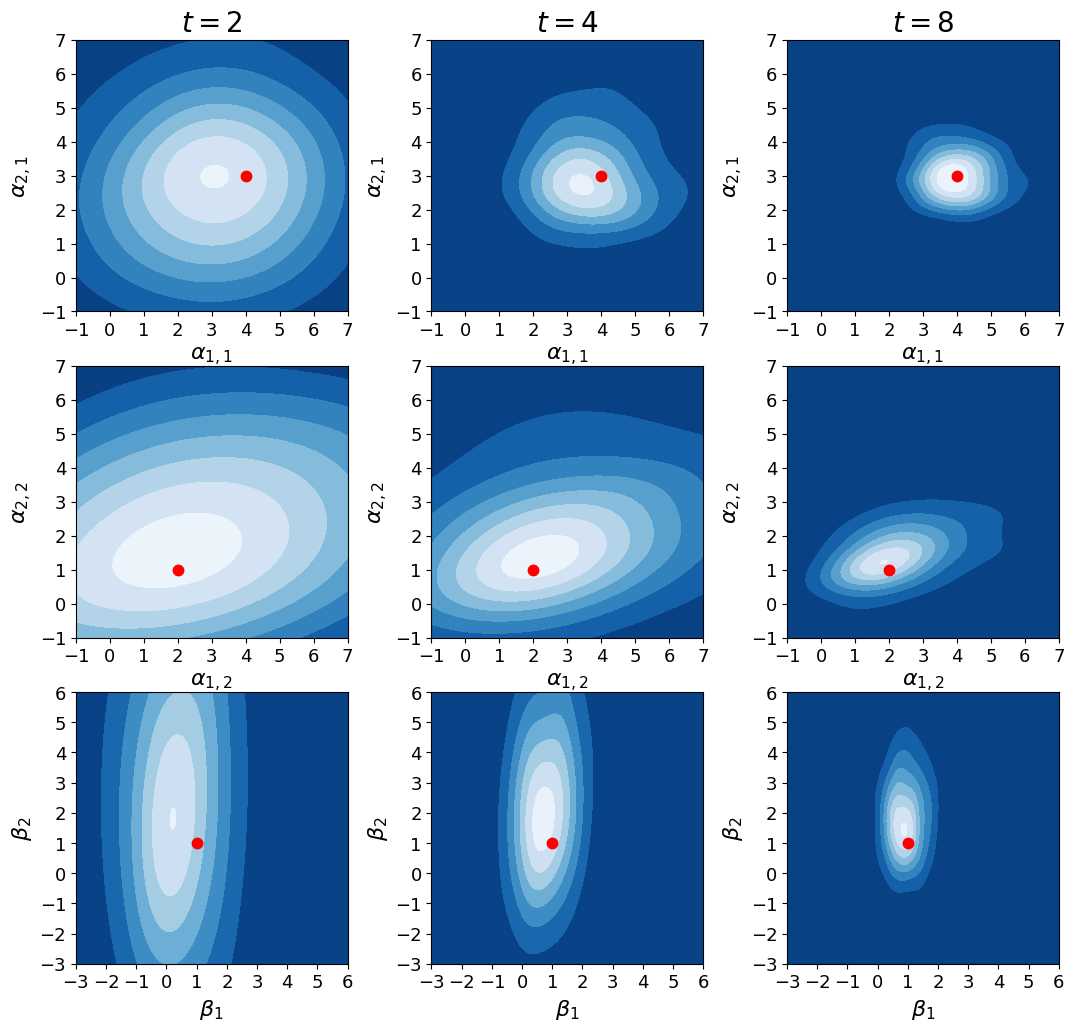

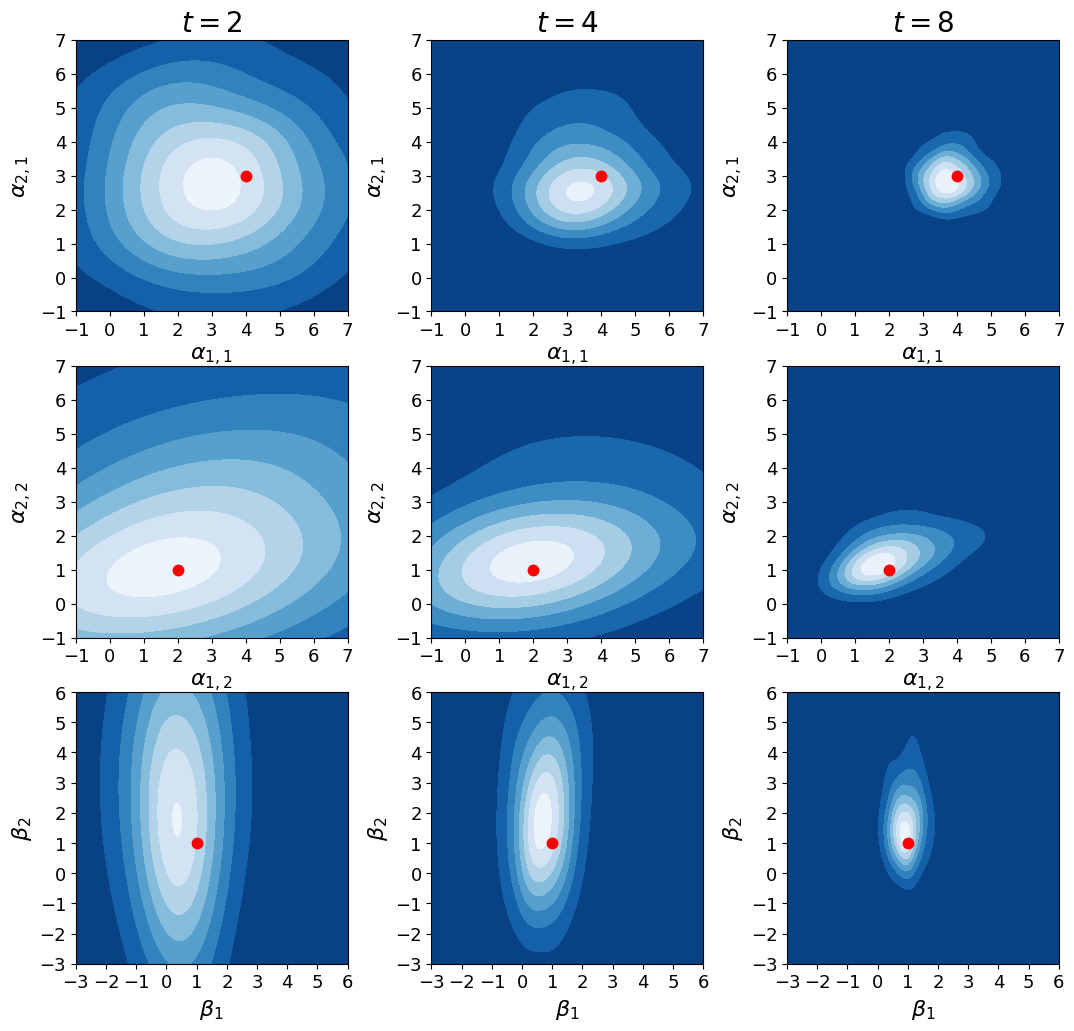

In [11]:
for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/estimate_' + regime + '.npy', 'rb') as f:
        estimate = np.load(f)

    fig, axes = plt.subplots(3, 3, figsize=(13, 12), squeeze=False)
    for log2t in range(1, 4):
        for n in range(2):
            for m in range(1):
                ax = axes[n, log2t - 1]
                x = estimate[:, log2t - 1, n * 3 + m]
                y = estimate[:, log2t - 1, n * 3 + m + 1]
                mask = (abs(x) < 100) & (abs(y) < 100)
                x_clean = x[mask]
                y_clean = y[mask]

                k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
                xi, yi = np.mgrid[-1:7:100 * 1j, -1:7:100 * 1j]
                zi = k(np.vstack([xi.flatten(), yi.flatten()]))

                ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

                ax.set_xticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.set_yticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.tick_params(axis='both', labelsize=13)
                ax.set_xlabel(r'$\alpha_{%i,%i}$' % (2 * m + 1, n + 1), fontsize=16)
                ax.set_ylabel(r'$\alpha_{%i,%i}$' % (2 * m + 2, n + 1), fontsize=16)
                ax.plot(X_sim.Q_get()[n][2 * m][2 * m], X_sim.Q_get()[n][2 * m + 1][2 * m + 1], color='red', marker='.', markersize=15)
                ax.set_box_aspect(1)

                if n == 0 and m == 0:
                    ax.set_title(r'$t = %i$' % 2 ** log2t, fontsize=20)

        ax = axes[2, log2t - 1]
        x = estimate[:, log2t - 1, 2]
        y = estimate[:, log2t - 1, 5]
        mask = (abs(x) < 100) & (abs(y) < 100)
        x_clean = x[mask]
        y_clean = y[mask]

        k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
        xi, yi = np.mgrid[-3:6:100 * 1j, -3:6:100 * 1j]
        zi = k(np.vstack([xi.flatten(), yi.flatten()]))

        ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

        ax.set_xticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.set_yticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.tick_params(axis='both', labelsize=13)
        ax.set_xlabel(r'$\beta_{%i}$' % 1, fontsize=16)
        ax.set_ylabel(r'$\beta_{%i}$' % 2, fontsize=16)
        ax.plot(1, 1, color='red', marker='.', markersize=15)
        ax.set_box_aspect(1)

    fig.savefig('./data/LOBSTERdata/output/sim/estimate_' + regime + '.eps', bbox_inches='tight', format='eps')

## Cells 13–15: Predictive Performance Study (Section 4.2, Figures 8–19)

Evaluates all forecasting models on a **complete graph with 5 nodes** (10 edges, Figure 6).

**True model:** $\text{grOU}(1,[1])$ with:
- $\alpha = 5$ for one selected edge $e^*$, $\alpha = 1$ for the remaining 9 edges
- $\beta = 2$ for all neighborhood stages (strong network interaction)

**Driving noise:** Compound Poisson, rate $\lambda = 1$, jump sizes $\mathcal{N}(0, \sigma^2 I_{10})$

| Cell | Jump variance $\sigma^2$ | Figures |
|------|--------------------------|---------|
| 13 | $\sigma^2 = 1$ | 8, 11, 14, 17 |
| 14 | $\sigma^2 = 5$ | 9, 12, 15, 18 |
| 15 | $\sigma^2 = 10$ | 10, 13, 16, 19 |

**Three misspecification scenarios** (Section 4.3):
- `correct`: Full network (all 10 edges)
- `missing_5`: Omit the dominant edge ($\alpha = 5$)
- `missing_1`: Omit a weakly persistent edge ($\alpha = 1$)

**Grid parameters:** $T = 3$, $N = 3^7$ steps, $\Delta_P = 3^{-6}$, $\Delta_Q = 3^{-2}$ (ratio 81)

> The `model_pred` calls are commented out as results are pre-computed. Uncomment to re-run.

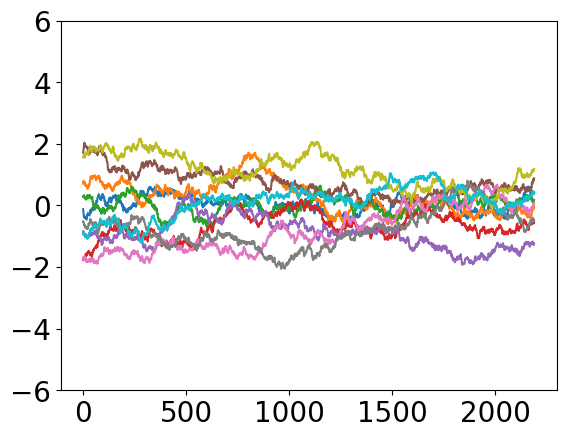

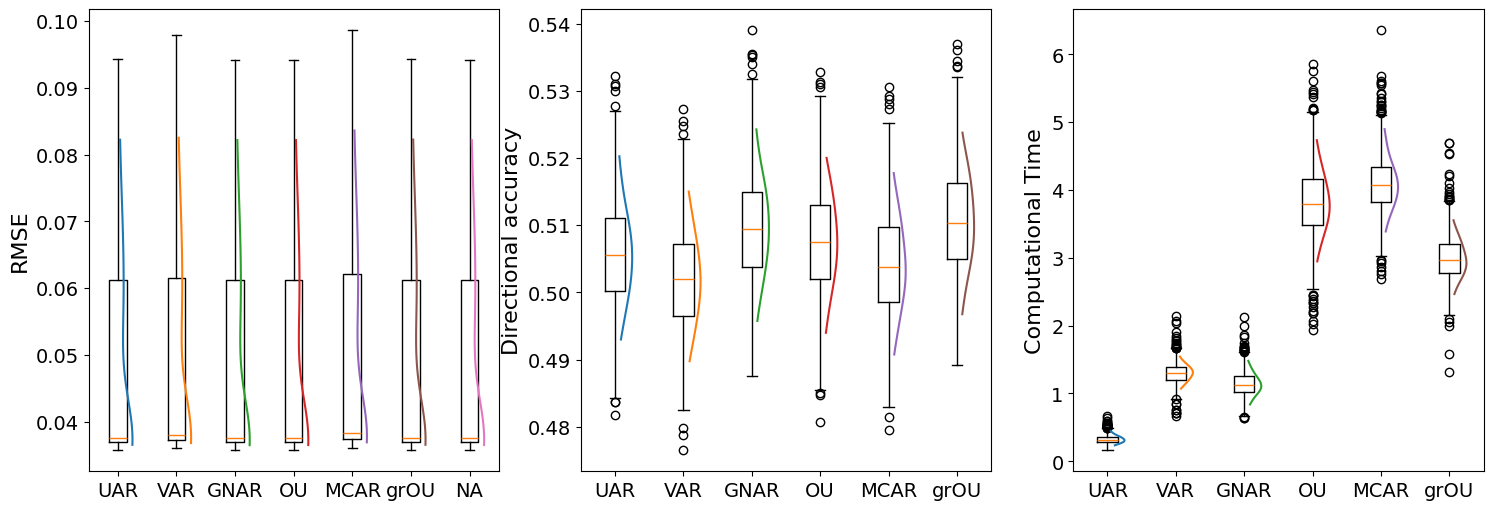

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049833  0.050137  0.049800  0.049815  0.050462   
RMSE_std                   0.016512  0.016499  0.016514  0.016513  0.016645   
Directional_accuracy_mean  0.505724  0.501967  0.509640  0.507395  0.504055   
Directional_accuracy_std   0.008113  0.007812  0.008412  0.008215  0.008271   
Computational_time_mean    0.328300  1.302185  1.144029  3.816535  4.097527   
Computational_time_std     0.066800  0.156232  0.195177  0.543190  0.453378   

                               grOU        NA  
RMSE_mean                  0.049866  0.049804  
RMSE_std                   0.016505  0.016513  
Directional_accuracy_mean  0.510528       NaN  
Directional_accuracy_std   0.008157       NaN  
Computational_time_mean    2.995075       NaN  
Computational_time_std     0.349065       NaN  


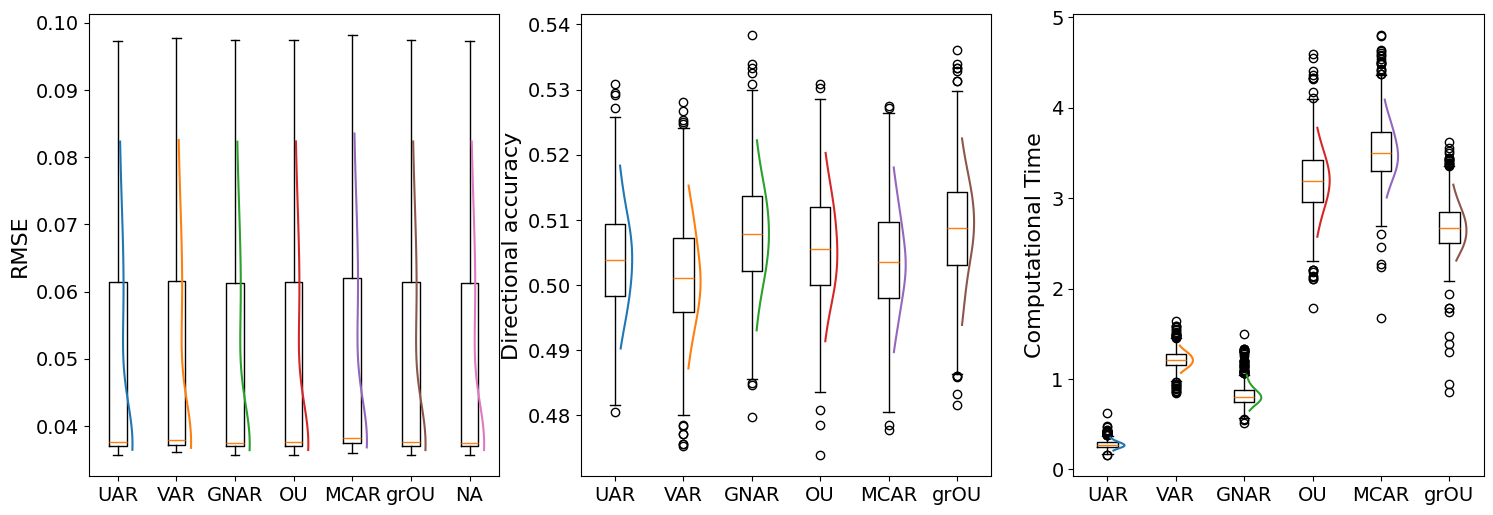

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049820  0.050088  0.049787  0.049831  0.050373   
RMSE_std                   0.016649  0.016635  0.016651  0.016679  0.016780   
Directional_accuracy_mean  0.503990  0.501297  0.507898  0.505878  0.503678   
Directional_accuracy_std   0.008435  0.008523  0.008615  0.008681  0.008561   
Computational_time_mean    0.275100  1.213539  0.822689  3.187566  3.521566   
Computational_time_std     0.045911  0.099584  0.124599  0.371718  0.345426   

                               grOU        NA  
RMSE_mean                  0.049809  0.049783  
RMSE_std                   0.016645  0.016648  
Directional_accuracy_mean  0.508571       NaN  
Directional_accuracy_std   0.008653       NaN  
Computational_time_mean    2.684526       NaN  
Computational_time_std     0.281621       NaN  


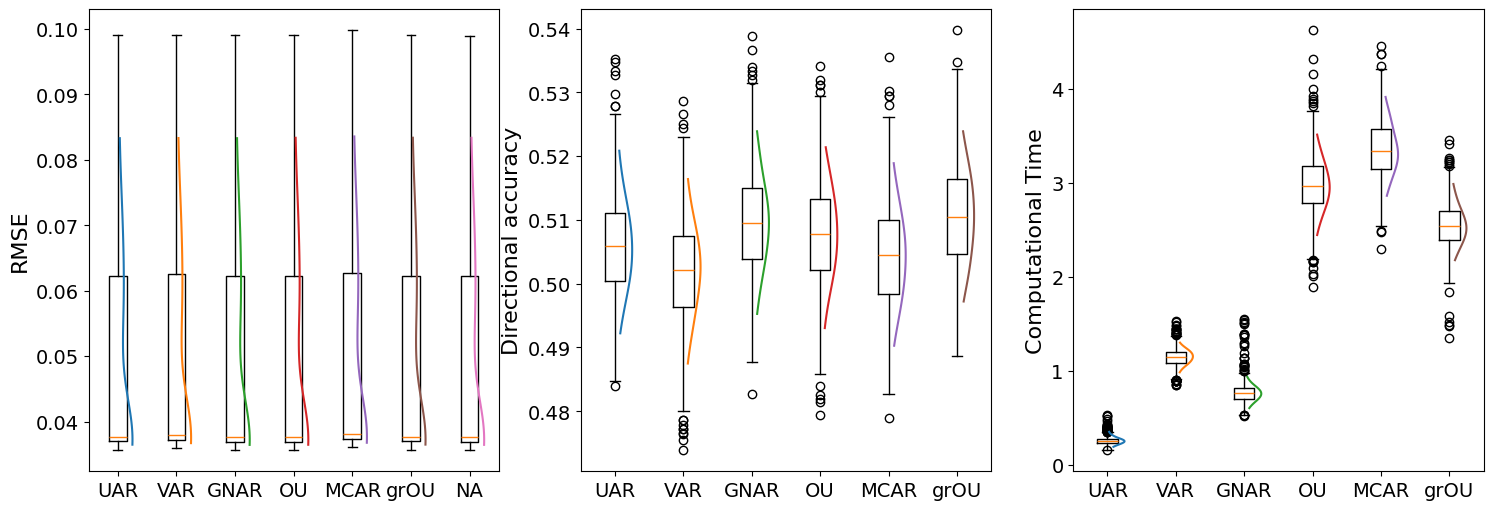

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.049939  0.050205  0.049908  0.049925  0.050443   
RMSE_std                   0.016595  0.016584  0.016598  0.016594  0.016696   
Directional_accuracy_mean  0.505941  0.501984  0.509549  0.507621  0.504385   
Directional_accuracy_std   0.008484  0.008523  0.008598  0.008533  0.008619   
Computational_time_mean    0.257933  1.146982  0.767245  2.981959  3.367255   
Computational_time_std     0.047990  0.097110  0.119776  0.327110  0.320402   

                               grOU        NA  
RMSE_mean                  0.049966  0.049911  
RMSE_std                   0.016588  0.016597  
Directional_accuracy_mean  0.510488       NaN  
Directional_accuracy_std   0.008340       NaN  
Computational_time_mean    2.554413       NaN  
Computational_time_std     0.251393       NaN  


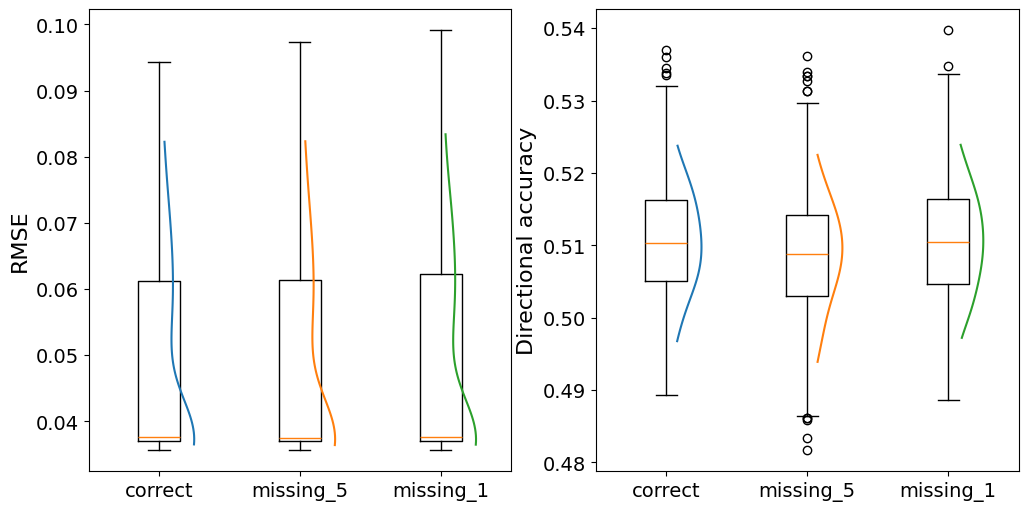

In [3]:
# Scale = 1, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_1_beta_2_rate_1', scale=1, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

'''
# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_1_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_1_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_1_beta_2_rate_1')
'''

boxplot_(data_sim, 'scale_1_beta_2_rate_1')

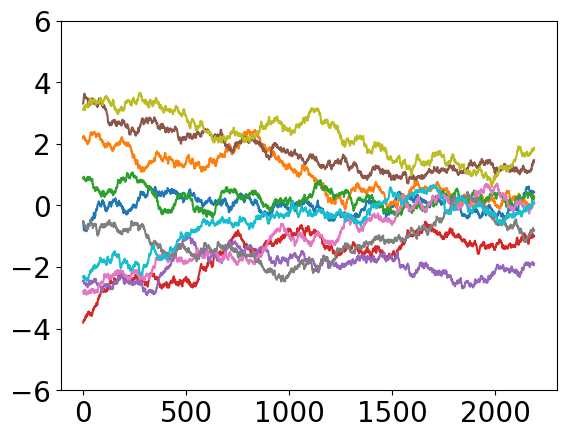

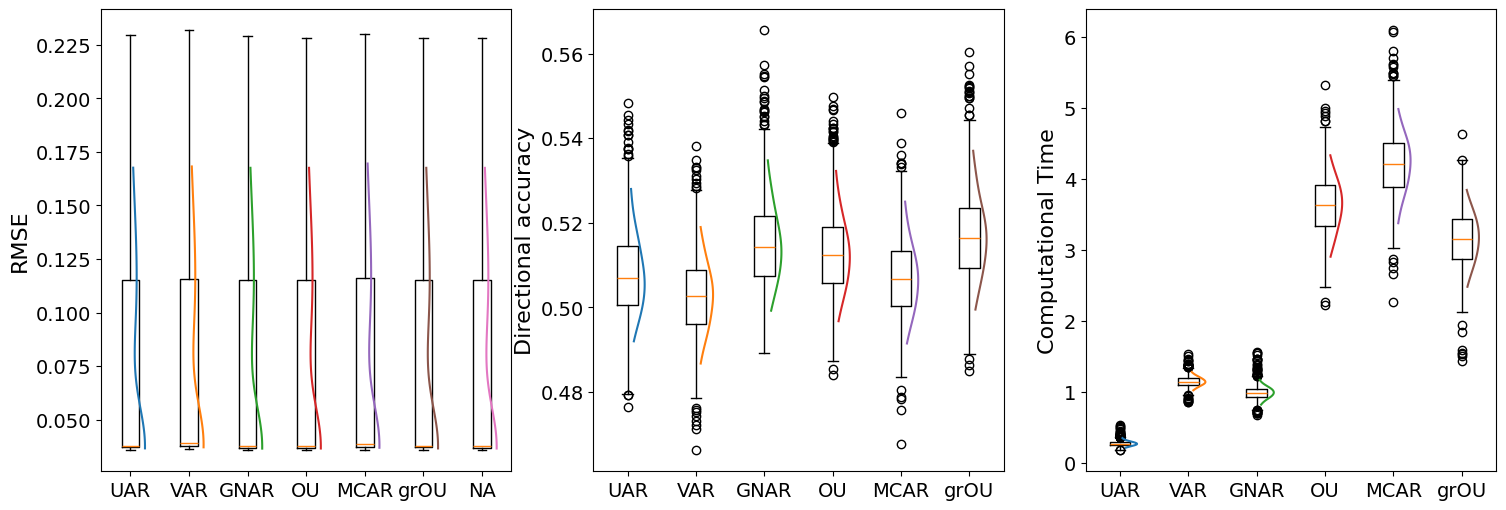

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.076693  0.077482  0.076611  0.076624  0.077537   
RMSE_std                   0.049143  0.048994  0.049159  0.049145  0.049495   
Directional_accuracy_mean  0.507958  0.502773  0.515208  0.512911  0.506918   
Directional_accuracy_std   0.010798  0.009872  0.010997  0.010552  0.009933   
Computational_time_mean    0.276935  1.148586  0.995034  3.632447  4.208465   
Computational_time_std     0.042671  0.081637  0.111228  0.437485  0.488270   

                               grOU        NA  
RMSE_mean                  0.076682  0.076616  
RMSE_std                   0.049130  0.049153  
Directional_accuracy_mean  0.516993       NaN  
Directional_accuracy_std   0.011409       NaN  
Computational_time_mean    3.157189       NaN  
Computational_time_std     0.424228       NaN  


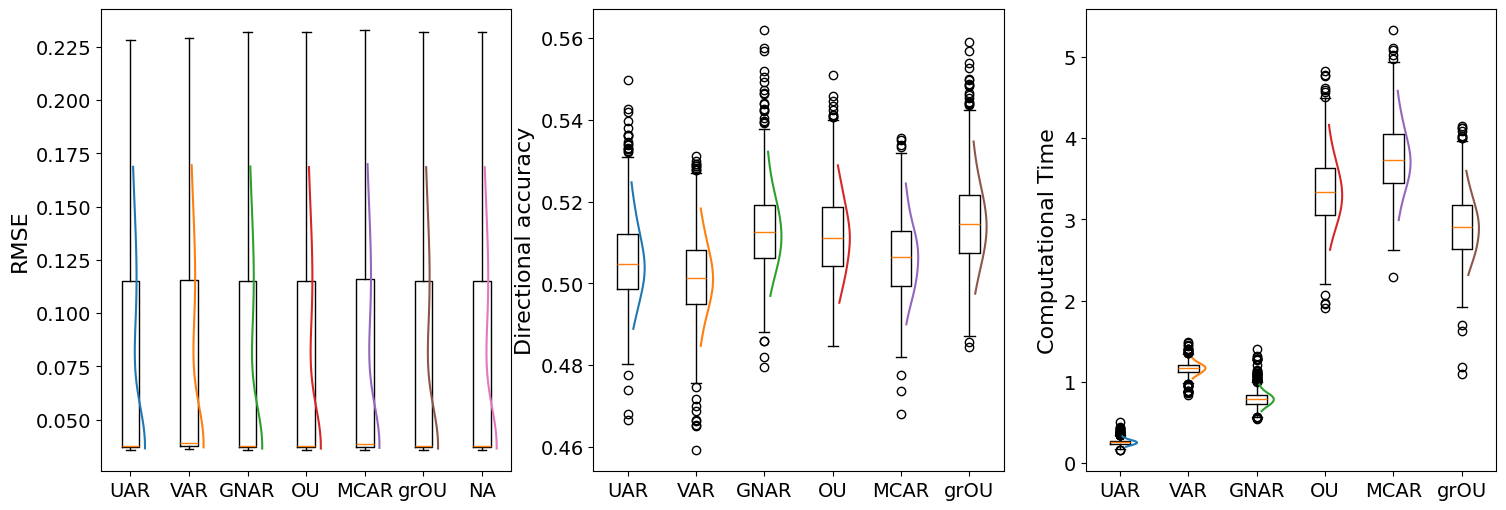

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.076613  0.077295  0.076529  0.076538  0.077321   
RMSE_std                   0.049422  0.049298  0.049438  0.049421  0.049717   
Directional_accuracy_mean  0.505523  0.501459  0.513108  0.511664  0.506531   
Directional_accuracy_std   0.010800  0.010352  0.010825  0.010496  0.010228   
Computational_time_mean    0.259421  1.165557  0.794539  3.350234  3.756197   
Computational_time_std     0.040627  0.080684  0.105915  0.445407  0.464658   

                               grOU        NA  
RMSE_mean                  0.076530  0.076520  
RMSE_std                   0.049424  0.049427  
Directional_accuracy_mean  0.515211       NaN  
Directional_accuracy_std   0.011245       NaN  
Computational_time_mean    2.915133       NaN  
Computational_time_std     0.397746       NaN  


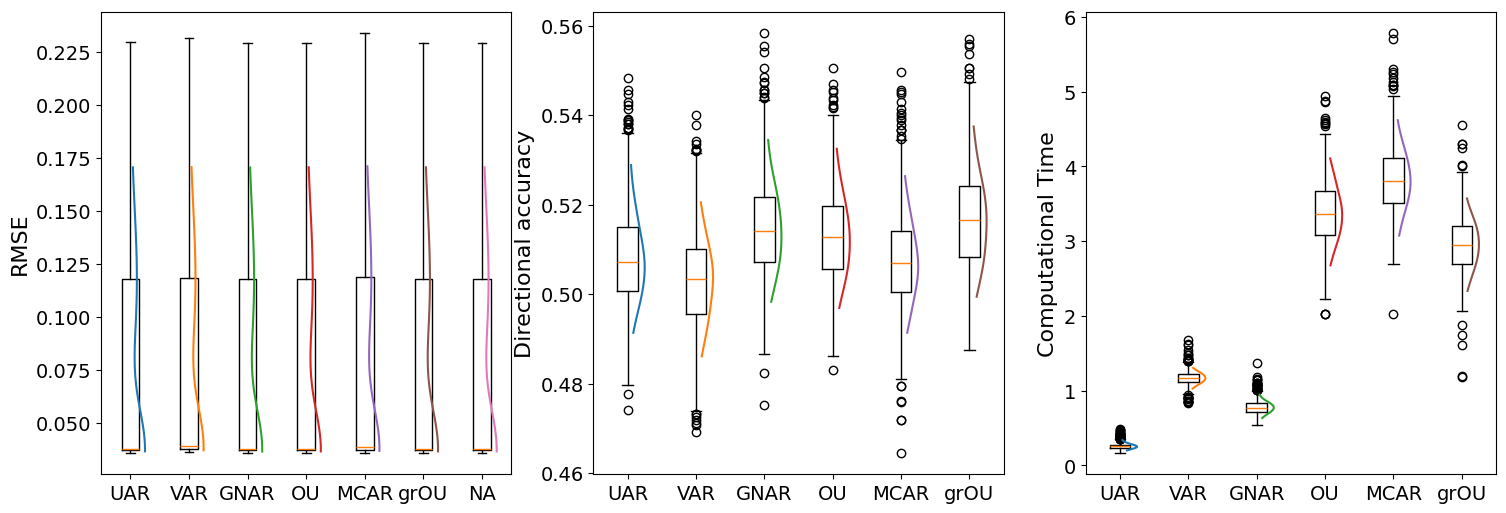

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.077018  0.077691  0.076941  0.076947  0.077688   
RMSE_std                   0.049378  0.049252  0.049395  0.049378  0.049650   
Directional_accuracy_mean  0.508240  0.503005  0.514700  0.513161  0.507598   
Directional_accuracy_std   0.011201  0.010867  0.011160  0.010752  0.010928   
Computational_time_mean    0.260597  1.170167  0.779923  3.382713  3.825777   
Computational_time_std     0.043893  0.092590  0.097569  0.436147  0.468688   

                               grOU        NA  
RMSE_mean                  0.076995  0.076942  
RMSE_std                   0.049362  0.049389  
Directional_accuracy_mean  0.516984       NaN  
Directional_accuracy_std   0.011512       NaN  
Computational_time_mean    2.951054       NaN  
Computational_time_std     0.386919       NaN  


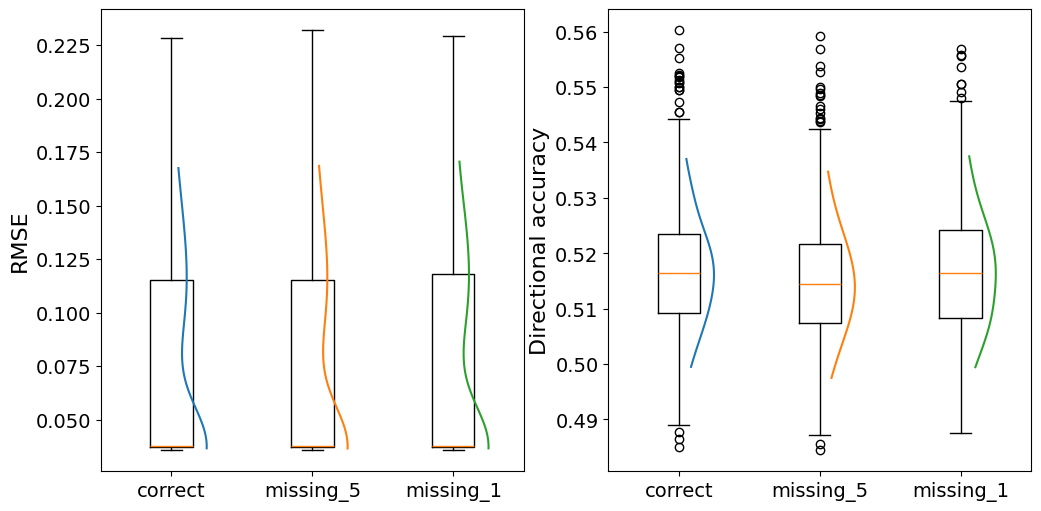

In [4]:
# Scale = 5, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_5_beta_2_rate_1', scale=5, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

'''
# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_5_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_5_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_5_beta_2_rate_1')
'''

boxplot_(data_sim, 'scale_5_beta_2_rate_1')

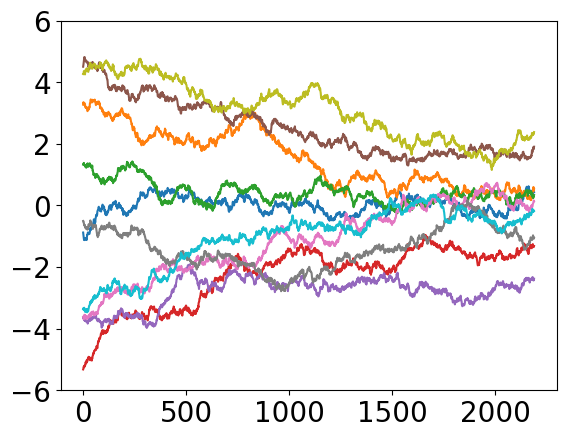

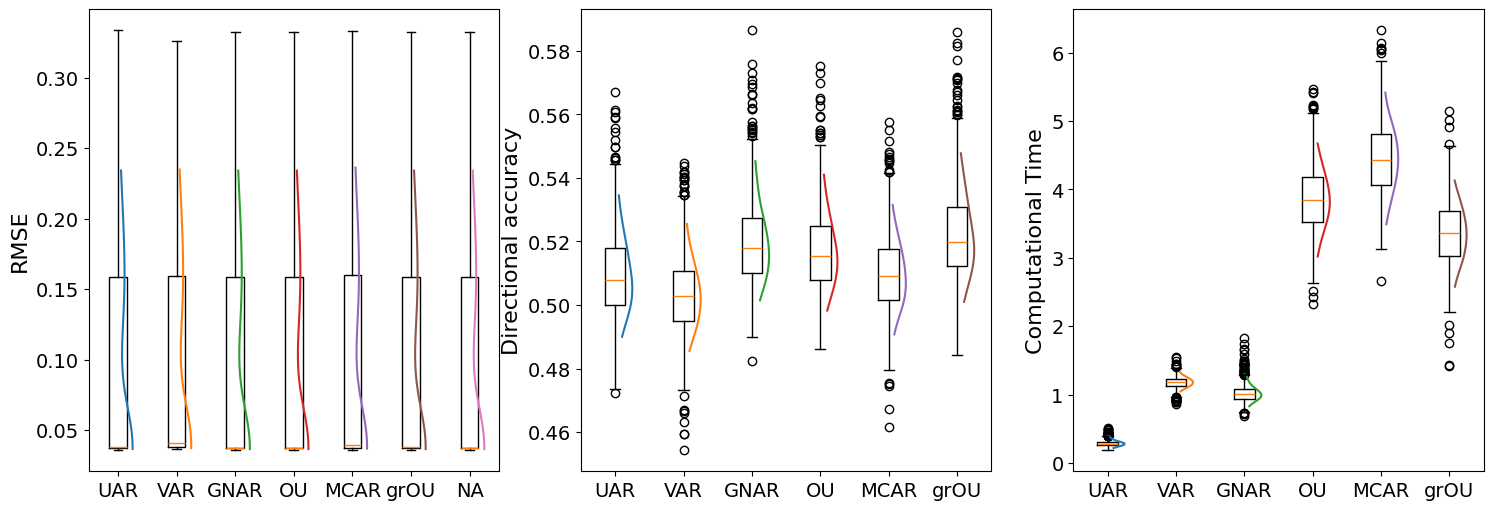

correct
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.098108  0.099480  0.097968  0.097994  0.099157   
RMSE_std                   0.074824  0.074495  0.074864  0.074852  0.075377   
Directional_accuracy_mean  0.509559  0.503391  0.519970  0.517285  0.509834   
Directional_accuracy_std   0.013913  0.012340  0.013744  0.013245  0.012461   
Computational_time_mean    0.288018  1.180614  1.021143  3.846513  4.438482   
Computational_time_std     0.048190  0.087655  0.133523  0.497196  0.555032   

                               grOU        NA  
RMSE_mean                  0.098045  0.097975  
RMSE_std                   0.074805  0.074851  
Directional_accuracy_mean  0.522119       NaN  
Directional_accuracy_std   0.014836       NaN  
Computational_time_mean    3.349956       NaN  
Computational_time_std     0.480883       NaN  


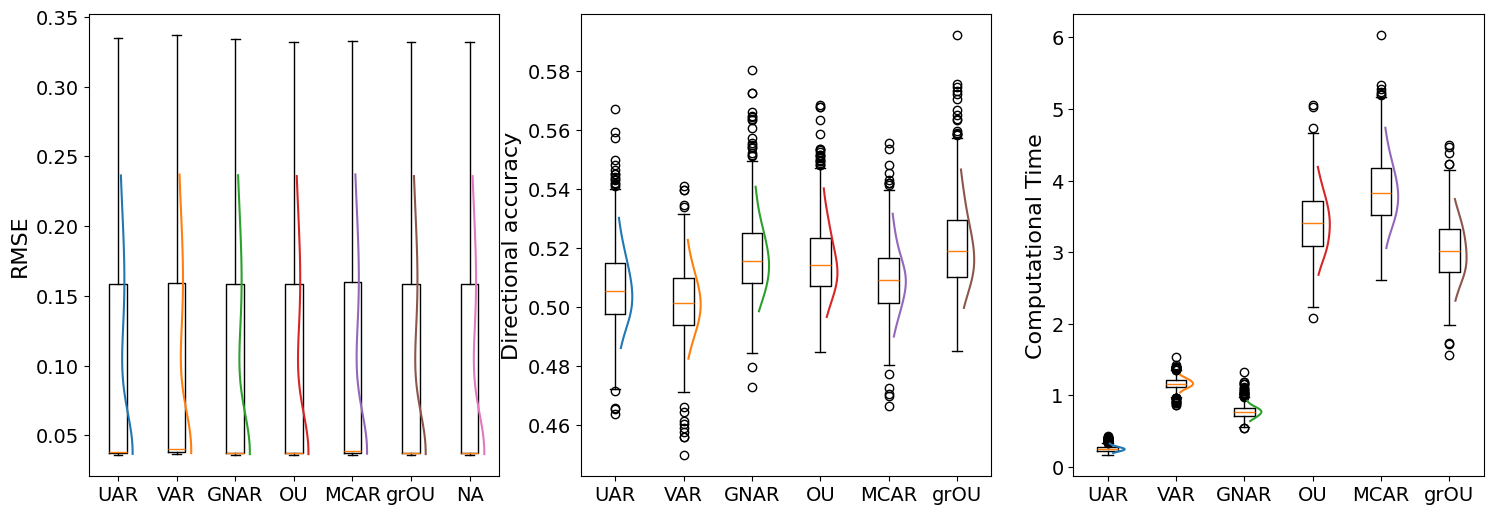

missing_5
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.097978  0.099165  0.097836  0.097854  0.098839   
RMSE_std                   0.075195  0.074910  0.075234  0.075216  0.075659   
Directional_accuracy_mean  0.506584  0.501834  0.517305  0.515896  0.509663   
Directional_accuracy_std   0.013546  0.012305  0.013299  0.013021  0.012331   
Computational_time_mean    0.255403  1.166008  0.773303  3.414966  3.859655   
Computational_time_std     0.040532  0.078042  0.090088  0.456692  0.491409   

                               grOU        NA  
RMSE_mean                  0.097835  0.097821  
RMSE_std                   0.075202  0.075216  
Directional_accuracy_mean  0.520717       NaN  
Directional_accuracy_std   0.014490       NaN  
Computational_time_mean    3.020852       NaN  
Computational_time_std     0.429500       NaN  


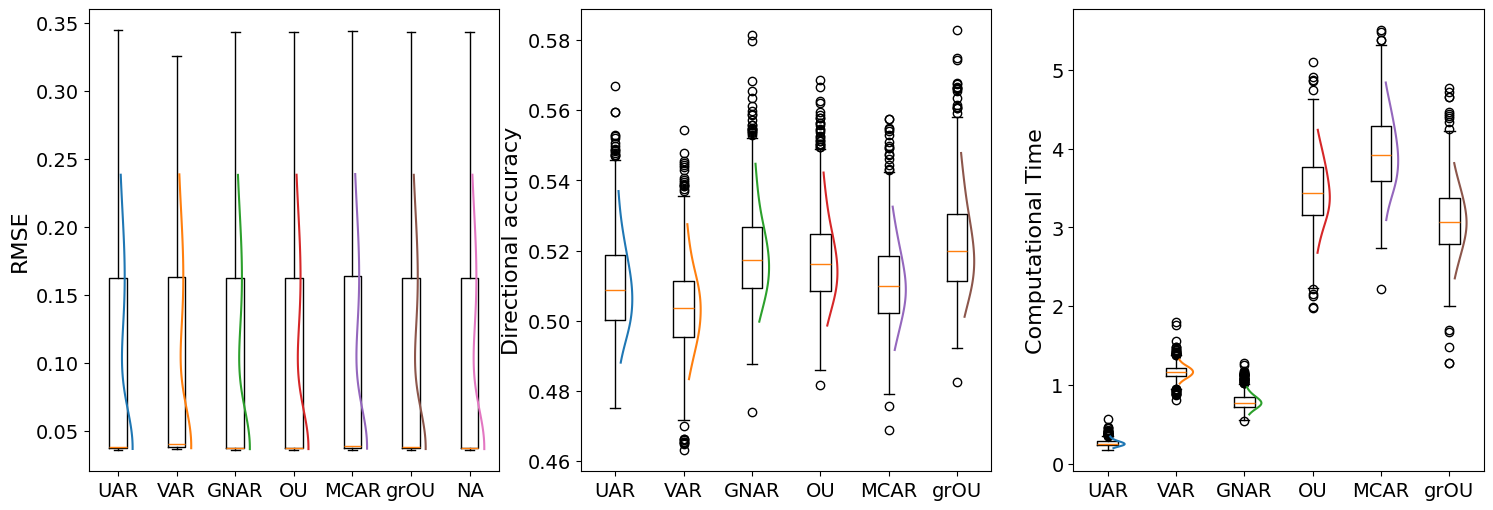

missing_1
                                UAR       VAR      GNAR        OU      MCAR  \
RMSE_mean                  0.098523  0.099684  0.098391  0.098390  0.099336   
RMSE_std                   0.075160  0.074869  0.075199  0.075182  0.075580   
Directional_accuracy_mean  0.509897  0.503996  0.519103  0.517531  0.510729   
Directional_accuracy_std   0.014266  0.013325  0.013862  0.013200  0.012709   
Computational_time_mean    0.260988  1.168161  0.787207  3.453068  3.949352   
Computational_time_std     0.044650  0.094230  0.105698  0.470422  0.512624   

                               grOU        NA  
RMSE_mean                  0.098452  0.098391  
RMSE_std                   0.075146  0.075188  
Directional_accuracy_mean  0.521895       NaN  
Directional_accuracy_std   0.014550       NaN  
Computational_time_mean    3.078896       NaN  
Computational_time_std     0.450489       NaN  


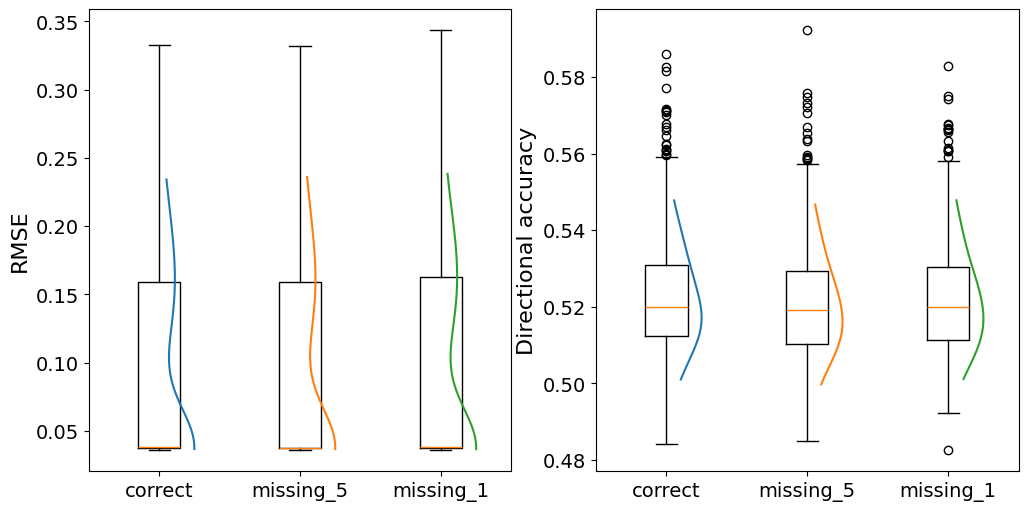

In [5]:
# Scale = 10, beta = 2, rate = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1], 10, 1, adj_L_sim, W_C_sim, gamma, 'data\\LOBSTERdata\\output\\sim\\scale_10_beta_2_rate_1', scale=10, T=3)
X_sim.alpha_set(np.array([[5,1,1,1,1,1,1,1,1,1]]))
X_sim.beta_set([[2]])
X_sim.Q_matrix()
data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

'''
# Correct Specification
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='correct', scenario='scale_10_beta_2_rate_1')

# Missing alpha = 5
adj_sim = adj_to_line_graph([[0,0,1,1,1],[0,0,1,1,1],[1,1,0,1,1],[1,1,1,0,1],[1,1,1,1,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_5', scenario='scale_10_beta_2_rate_1')

# Missing alpha = 1
adj_sim = adj_to_line_graph([[0,1,1,1,1],[1,0,1,1,1],[1,1,0,1,1],[1,1,1,0,0],[1,1,1,0,0]], ['a','b','c','d','e'])
model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=81, gamma=gamma, label='missing_1', scenario='scale_10_beta_2_rate_1')
'''

boxplot_(data_sim, 'scale_10_beta_2_rate_1')